# インポート

In [1]:
%load_ext autoreload
%autoreload 2

from MAM_basic_noVM import SoldierCrabSwarm_noVM

# from model.MAM_basic import SoldierCrabSwarm
from model.MAM_support import SwarmVisualizer
from model.MAM_noVM import SoldierCrabSwarm_noVM
from model.MAM_basic_step import SoldierCrabSwarm_step
from model.MAM_basic_step_noVM import SoldierCrabSwarm_step_noVM
from model.MAM_basic_step_pop import SoldierCrabSwarm_step_pop
from model.MAM_basic_step_pop_noVM import SoldierCrabSwarm_step_pop_noVM
from model.MAM_basic_step_popnew import SoldierCrabSwarm_step_popnew
from model.MAM_basic_step_recalc import SoldierCrabSwarm_step_recalc
from model.MAM_basic_step_popVM import SoldierCrabSwarm_step_popVM
from model.MAM_basic_step_pop_dynamic import SoldierCrabSwarm_step_pop_dynamic
from model.MAM_basic_step_pop_v2 import SoldierCrabSwarm_step_pop_v2
from model.MAM_basic_Murakami import SoldierCrabSwarm_Murakami

from MAM_basic_ex_fix import SoldierCrabSwarm_ex_fix
from MAM_basic_ex_v2 import SoldierCrabSwarm_ex_v2

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Meiryo"
plt.rcParams["axes.unicode_minus"] = False

import matplotlib.animation as animation
from matplotlib.animation import PillowWriter
from IPython.display import Image, display, HTML

from tqdm import tqdm

# スナップショットを記録

### 単純に複数のスナップショットを記録する

In [8]:
class SwarmVisualizer:
    """
    SoldierCrabSwarm のシミュレーションを実行したり、スナップショットをとったりする補助クラス

    使い方
    >>> swarm = SoldierCrabSwarm()      パラメータを変更する場合は括弧内に代入する
    >>> viz = SwarmVisualizer(swarm)    
    >>> viz.summary()                   パラメータ設定を表示する
    >>> viz.animate()                   n_stepで実行step数、pathでファイル名、show=Falseで表示しないなど設定できる

    >>> viz.save_snapshot(frame=)       指定したframeのスナップショットを保存
    """

    def __init__(self, swarm, arrow_len=0.8, figsize=(6, 6)):
        self.swarm = swarm
        self.arrow_len = arrow_len
        self.figsize = figsize

        # run() で記録される履歴
        self.positions_history = None
        self.theta_history = None

        # build_animation() で作られる描画関連オブジェクト
        self.fig = None
        self.ax = None
        self.quiv = None
        self.step_text = None
        self.ani = None

    # ------------------------------------------------------------------
    # パラメータ表示
    # ------------------------------------------------------------------
    def summary(self):
        """
        現在のモデル状態の要約を表示する
        """
        s = self.swarm
        print("=== パラメータ設定 ===")
        print(f"格子空間サイズ S       : {s.S} x {s.S} (トーラス境界)")
        print(f"エージェント数 N       : {s.N}")
        print(f"基本ベクトル長 L       : {s.L}")
        print(f"可能的遷移数 P         : {s.P}")
        print(f"変異角 alpha           : {s.alpha}")
        print(f"追従者近傍半径 R(Nf)   : {s.R_Nf}")
        print(f"速度一致近傍半径 R(M)  : {s.R_M}")
        print(f"人気度閾値 c           : {s.c}")
        print(f"シード値 seed          : {s.seed}")
        # print(f"壁監視近傍半径 N_W     : {s.N_W}")
        
        # print(f"現在ステップ t         : {s.t}")

    # ------------------------------------------------------------------
    # ワンストップ実行：シミュレーション実行 → 描画 → 保存（→ 表示）
    # ------------------------------------------------------------------
    def animate(self, n_steps=300, path="soldier_crab_swarm.gif", fps=10,
                interval=100, show=True):
        """
        アニメーションを実行して保存する
        fps GIFのフレームレート
        interval アニメーション再生時のフレーム間隔（ミリ秒）。GIF自体の速度は fps で決まる。
        """
        self.run(n_steps)
        self.build_animation(interval=interval)
        self.ani.save(path, writer=PillowWriter(fps=fps))

        if show:
            html = HTML(self.ani.to_jshtml())
            display(html)

        plt.close(self.fig)
        return path

        # self.run(n_steps)
        # if show:
        #     return self.show(path=path, fps=fps, interval=interval)
        # return self.save(path=path, fps=fps, interval=interval)
    
    def save_snapshot(self, frame, path=None, dpi=150, show=True):
        """
        frameステップ分シミュレーションを実行し、その時点の状態を保存・表示する。
        """
        self.run(frame)

        if path is None:
            path = f"snapshot_step{frame:04d}.png"

        fig, ax = plt.subplots(figsize=self.figsize)
        self._draw_frame(len(self.positions_history) - 1, ax)
        fig.savefig(path, dpi=dpi, bbox_inches="tight")

        if show:
            plt.show()
        plt.close(fig)

        return path
    
    # ------------------------------------------------------------------
    # 内部処理に使用した関数たち
    # ------------------------------------------------------------------
    def run(self, n_steps):
        """
        n_steps 分シミュレーションを実行しながら、各ステップの position と theta を記録する。
        swarm.run() は position しか記録できないため、矢印描画に使うthetaもここで一緒に保存している。
        """
        positions_history = [self.swarm.position.copy()]
        theta_history = [self.swarm.theta.copy()]

        for _ in range(n_steps):
            self.swarm.step()
            positions_history.append(self.swarm.position.copy())
            theta_history.append(self.swarm.theta.copy())

        self.positions_history = np.array(positions_history)  # (n_steps+1, N, 2)
        self.theta_history = np.array(theta_history)           # (n_steps+1, N)
        return self
    
    # ------------------------------------------------------------------
    # 描画関連
    # ------------------------------------------------------------------
    def _build_figure(self):
        S = self.swarm.S
        fig, ax = plt.subplots(figsize=self.figsize)
        ax.set_xlim(-0.5, S - 0.5)
        ax.set_ylim(-0.5, S - 0.5)
        ax.set_aspect("equal")
        ax.set_title("Soldier Crab Swarm")

        x0 = self.positions_history[0][:, 0]
        y0 = self.positions_history[0][:, 1]
        th0 = self.theta_history[0]
        u0 = self.arrow_len * np.cos(th0)
        v0 = self.arrow_len * np.sin(th0)

        quiv = ax.quiver(
            x0, y0, u0, v0,
            angles="xy", scale_units="xy", scale=1,
            width=0.004, color="tab:blue",
        )
        step_text = ax.text(0.02, 0.98, "", transform=ax.transAxes, va="top")

        self.fig, self.ax, self.quiv, self.step_text = fig, ax, quiv, step_text

    def _update(self, frame):
        x = self.positions_history[frame][:, 0]
        y = self.positions_history[frame][:, 1]
        th = self.theta_history[frame]
        u = self.arrow_len * np.cos(th)
        v = self.arrow_len * np.sin(th)

        self.quiv.set_offsets(np.column_stack([x, y]))
        self.quiv.set_UVC(u, v)
        self.step_text.set_text(f"step = {frame}")
        return self.quiv, self.step_text

    # ------------------------------------------------------------------
    # 保存・表示関連
    # ------------------------------------------------------------------
    def build_animation(self, interval=100):
        """FuncAnimation オブジェクトを作成して返す（run() 実行後に呼ぶ）"""
        if self.positions_history is None:
            raise RuntimeError(
                "履歴がありません。先に animator.run(n_steps) を呼んでください。"
            )

        self._build_figure()
        self.ani = animation.FuncAnimation(
            self.fig,
            self._update,
            frames=len(self.positions_history),
            interval=interval,
            blit=False,
        )
        return self.ani

    # def save(self, path="soldier_crab_swarm.gif", fps=10, interval=100):
    #     """アニメーションをGIFとして保存する。パスを返す。"""
    #     if self.ani is None:
    #         self.build_animation(interval=interval)

    #     self.ani.save(path, writer=PillowWriter(fps=fps))
    #     plt.close(self.fig)
    #     return path

    # def show(self, path="soldier_crab_swarm.gif", fps=10, interval=100):
    #     """GIFとして保存しつつ、Notebook内にも同じものを表示する。"""
    #     gif_path = self.save(path=path, fps=fps, interval=interval)
    #     display(Image(filename=gif_path))
    #     return gif_path

    def _draw_frame(self, frame, ax):
        """指定したステップの状態を ax に描画する（矢印のみ、内部利用）"""
        S = self.swarm.S
        ax.set_xlim(-0.5, S - 0.5)
        ax.set_ylim(-0.5, S - 0.5)
        ax.set_aspect("equal")
        ax.set_title("Soldier Crab Swarm")
 
        x = self.positions_history[frame][:, 0]
        y = self.positions_history[frame][:, 1]
        th = self.theta_history[frame]
        u = self.arrow_len * np.cos(th)
        v = self.arrow_len * np.sin(th)
 
        ax.quiver(
            x, y, u, v,
            angles="xy", scale_units="xy", scale=1,
            width=0.004, color="tab:blue",
        )
        ax.text(0.02, 0.98, f"step = {frame}", transform=ax.transAxes, va="top")

In [ ]:
# 複数のスナップショットを取得する

from itertools import product

P_list = [1, 2, 5, 10, 20]
alpha_list = [0.3, 0.5, 0.7, 0.9]
frame_list = [50, 100, 150, 200]

for P, alpha, frame in product(P_list, alpha_list, frame_list):
    path = f"snapshot/snapshot{frame:03d}_P{P}_a{alpha:.1f}_seed1.png"

    # 実行
    swarm = SoldierCrabSwarm_ex_fix(P=P, alpha=alpha, seed=1)
    viz = SwarmVisualizer(swarm)
    viz.summary()
    viz.save_snapshot(frame=frame, path=path)

In [10]:
swarm = SoldierCrabSwarm_step_pop(P=2, alpha=0.1, N=2)
viz = SwarmVisualizer(swarm)
viz.summary()
viz.animate(n_steps=1000)

=== パラメータ設定 ===
格子空間サイズ S       : 50 x 50 (トーラス境界)
エージェント数 N       : 2
基本ベクトル長 L       : 4.0
可能的遷移数 P         : 2
変異角 alpha           : 0.1
追従者近傍半径 R(Nf)   : 2
速度一致近傍半径 R(M)  : 3
人気度閾値 c           : 2
シード値 seed          : None


'soldier_crab_swarm.gif'

### 軌跡を記録するスナップショット

In [2]:
def run_with_history(swarm, n_steps):
    """
    n_steps 分シミュレーションを実行しながら、各ステップの position を記録する。
    MAM_basic のモデル自体は一切いじらず、外側から position だけ記録している。
    """
    positions_history = [swarm.position.copy()]
    for _ in range(n_steps):
        swarm.step()
        positions_history.append(swarm.position.copy())
    return np.array(positions_history)  # shape: (n_steps+1, N, 2)

def plot_snapshot_with_trail(positions_history, S, step=None, tail_length=None,
                              figsize=(6, 6), marker_size=8, path=None, show=True):
    """
    論文1 Fig.8 のように、各エージェントを□で表示し、直近 tail_length ステップ分の
    軌跡を線で重ねて描画する。

    step        : 何ステップ目のスナップショットを撮るか（Noneなら最終ステップ）
    tail_length : 軌跡として遡るステップ数（Noneなら記録全期間を表示）
    """
    n_frames = positions_history.shape[0]
    if step is None:
        step = n_frames - 1

    start = 0 if tail_length is None else max(0, step - tail_length)
    trail = positions_history[start:step + 1]  # (T, N, 2)

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(-0.5, S - 0.5)
    ax.set_ylim(-0.5, S - 0.5)
    ax.set_aspect("equal")
    # ax.set_title(f"α = {swarm.alpha}, P = {swarm.P}, step = {step}")
    ax.set_title(f"step = {step}時点のスナップショット（直近{step - start}ステップの軌跡）")
    ax.set_xlabel("トーラス空間のX座標")
    ax.set_ylabel("トーラス空間のY座標")
    ax.text(0.98, 0.88, f"α = {swarm.alpha}, P = {swarm.P}", transform=ax.transAxes, va="bottom", ha="right")
    ax.set_xticks([])
    ax.set_yticks([])

    N = trail.shape[1]
    half = S / 2.0

    for k in range(N):
        xs = trail[:, k, 0].astype(float)
        ys = trail[:, k, 1].astype(float)

        # トーラスのラップをまたぐ箇所を NaN で分断（見た目のワープ線を防ぐ）
        dx = np.diff(xs)
        dy = np.diff(ys)
        wrap = (np.abs(dx) > half) | (np.abs(dy) > half)
        if wrap.any():
            wrap_idx = np.flatnonzero(wrap) + 1
            xs = np.insert(xs, wrap_idx, np.nan)
            ys = np.insert(ys, wrap_idx, np.nan)

        ax.plot(xs, ys, color="black", linewidth=0.6, alpha=0.7)

    # 現在地点を■でプロット
    x_now = trail[-1, :, 0]
    y_now = trail[-1, :, 1]
    ax.scatter(x_now, y_now, marker="s", s=marker_size, color="black")

    if path is not None:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig, ax

In [ ]:
path = "model.png"
swarm = SoldierCrabSwarm_step(N=100, S=50, L=4, P=10, alpha=0.7, R_Nf=2, R_M=3, c=2, seed=1)

history = run_with_history(swarm, n_steps=1000)

plot_snapshot_with_trail(history, S=swarm.S, step=1000, tail_length=20, path=path)

In [ ]:
from itertools import product

P_list = [1, 2, 5, 10, 20]
alpha_list = [0.3, 0.5, 0.7, 0.9]

for P, alpha in product(P_list, alpha_list):
    path = f"snapshot_P{P}_a{alpha:.1f}_round.png"

    swarm = SoldierCrabSwarm_ex_v2(N=100, S=50, L=4, P=P, alpha=alpha, R_Nf=2, R_M=3, c=2, seed=46,int_mode="round")

    history = run_with_history(swarm, n_steps=1000)

    plot_snapshot_with_trail(history, S=swarm.S, step=1000, tail_length=10, path=path)

### 軌跡をMP4で記録

In [3]:
%pip install imageio-ffmpeg tqdm

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.animation import FFMpegWriter
from IPython.display import Video, display
from tqdm.auto import tqdm

# ffmpeg がPCに入っていなくても動くように、imageio-ffmpeg 同梱のものを使う
try:
    import imageio_ffmpeg
    plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
except ImportError:
    pass


def animate_trail(positions_history, S, tail_length=30, frame_step=1,
                  figsize=(6, 6), marker_size=8, path="swarm_trail.mp4",
                  fps=10, dpi=100, title=None, show=True, embed=True):
    """
    plot_snapshot_with_trail と同じ描き方（□＋軌跡）を、mp4動画として保存する。
    毎フレーム、直近 tail_length ステップ分の軌跡を引き直す。

    frame_step : 何ステップごとに1フレーム描くか（長いシミュレーションは間引くと速い）
    title      : 図のタイトル（例: f"α = {swarm.alpha}, P = {swarm.P}"）
    embed      : True ならノートブックに動画を埋め込む（Colabは True 必須）
    """
    n_frames, N, _ = positions_history.shape
    half = S / 2.0

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(-0.5, S - 0.5)
    ax.set_ylim(-0.5, S - 0.5)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    if title is not None:
        ax.set_title(title)
    step_text = ax.text(0.02, 0.98, "", transform=ax.transAxes, va="top")

    # 各エージェント用の線オブジェクトを先に用意（毎フレーム作り直さない）
    lines = [ax.plot([], [], color="black", linewidth=0.6, alpha=0.7)[0] for _ in range(N)]
    scat = ax.scatter([], [], marker="s", s=marker_size, color="black")

    def _trail_xy(k, frame):
        start = max(0, frame - tail_length)
        xs = positions_history[start:frame + 1, k, 0].astype(float)
        ys = positions_history[start:frame + 1, k, 1].astype(float)

        # トーラスのラップをまたぐ箇所を NaN で分断
        dx = np.diff(xs)
        dy = np.diff(ys)
        wrap = (np.abs(dx) > half) | (np.abs(dy) > half)
        if wrap.any():
            wrap_idx = np.flatnonzero(wrap) + 1
            xs = np.insert(xs, wrap_idx, np.nan)
            ys = np.insert(ys, wrap_idx, np.nan)
        return xs, ys

    def _update(frame):
        for k in range(N):
            xs, ys = _trail_xy(k, frame)
            lines[k].set_data(xs, ys)

        scat.set_offsets(positions_history[frame, :, :2])
        step_text.set_text(f"step = {frame}")
        return lines + [scat, step_text]

    # 描画するステップ番号（最後のステップは必ず含める）
    frames = list(range(0, n_frames, frame_step))
    if frames[-1] != n_frames - 1:
        frames.append(n_frames - 1)

    ani = animation.FuncAnimation(fig, _update, frames=frames, blit=False)

    # 1フレームずつ ffmpeg に流すので、step数が多くてもメモリを食わない
    writer = FFMpegWriter(
        fps=fps, codec="libx264",
        extra_args=["-pix_fmt", "yuv420p"],  # どのプレイヤーでも再生できる形式
    )
    pbar = tqdm(total=len(frames), desc="動画書き出し中")
    ani.save(path, writer=writer, dpi=dpi,
             progress_callback=lambda i, n: pbar.update(1))
    pbar.close()
    plt.close(fig)

    if show:
        display(Video(path, embed=embed, width=500))

    return path

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\PC_User\Program\Research\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
from itertools import product

P_list = [1, 2, 5, 10, 20]
alpha_list = [0.3, 0.5, 0.7, 0.9]

for P, alpha in product(P_list, alpha_list):
    path = f"trail_P{P}_a{alpha:.1f}_floor.mp4"

    swarm = SoldierCrabSwarm_ex_v2(N=100, S=50, L=4, P=P, alpha=alpha, R_Nf=2, R_M=3, c=2, seed=46,int_mode="floor")
    positions_history = run_with_history(swarm, n_steps=1000)

    animate_trail(
        positions_history, swarm.S,
        tail_length=30,
        frame_step=1,     # 重いときは 2〜10 くらいに
        fps=30,
        path=path,
        title=f"α = {swarm.alpha}, P = {swarm.P}",
    )

動画書き出し中:  11%|█▏        | 23/201 [00:12<00:03, 45.42it/s]

In [17]:
P = 10
alpha = 0.1

path = f"trail_P{P}_a{alpha:.1f}_floor.mp4"

swarm = SoldierCrabSwarm_ex_v2(N=100, S=50, L=4, P=P, alpha=alpha, R_Nf=2, R_M=3, c=2, seed=46,int_mode="floor")
positions_history = run_with_history(swarm, n_steps=1000)

animate_trail(
    positions_history, swarm.S,
    tail_length=5,
    frame_step=5,     # 重いときは 2〜10 くらいに
    fps=10,
    path=path,
    title=f"α = {swarm.alpha}, P = {swarm.P}",
)

動画書き出し中: 100%|██████████| 201/201 [00:05<00:00, 34.54it/s]


'trail_P10_a0.1_floor.mp4'

### 軌跡を動画で記録

In [3]:
import matplotlib.animation as animation
from matplotlib.animation import PillowWriter
from IPython.display import HTML, display


def animate_trail(positions_history, S, tail_length=30, interval=100,
                   figsize=(6, 6), marker_size=8, path="swarm_trail.gif",
                   fps=10, show=True):
    """
    plot_snapshot_with_trail と同じ描き方（□＋軌跡）を、動画として保存する。
    毎フレーム、直近 tail_length ステップ分の軌跡を引き直す。
    """
    n_frames, N, _ = positions_history.shape
    half = S / 2.0

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(-0.5, S - 0.5)
    ax.set_ylim(-0.5, S - 0.5)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    step_text = ax.text(0.02, 0.98, "", transform=ax.transAxes, va="top")

    # 各エージェント用の線オブジェクトを先に用意（毎フレーム作り直さない）
    lines = [ax.plot([], [], color="black", linewidth=0.6, alpha=0.7)[0] for _ in range(N)]
    scat = ax.scatter([], [], marker="s", s=marker_size, color="black")

    def _trail_xy(k, frame):
        start = max(0, frame - tail_length)
        xs = positions_history[start:frame + 1, k, 0].astype(float)
        ys = positions_history[start:frame + 1, k, 1].astype(float)

        # トーラスのラップをまたぐ箇所を NaN で分断
        dx = np.diff(xs)
        dy = np.diff(ys)
        wrap = (np.abs(dx) > half) | (np.abs(dy) > half)
        if wrap.any():
            wrap_idx = np.flatnonzero(wrap) + 1
            xs = np.insert(xs, wrap_idx, np.nan)
            ys = np.insert(ys, wrap_idx, np.nan)
        return xs, ys

    def _update(frame):
        for k in range(N):
            xs, ys = _trail_xy(k, frame)
            lines[k].set_data(xs, ys)

        x_now = positions_history[frame, :, 0]
        y_now = positions_history[frame, :, 1]
        scat.set_offsets(np.column_stack([x_now, y_now]))
        step_text.set_text(f"step = {frame}")
        return lines + [scat, step_text]

    ani = animation.FuncAnimation(
        fig, _update, frames=n_frames, interval=interval, blit=False
    )

    if path is not None:
        ani.save(path, writer=PillowWriter(fps=fps))

    if show:
        display(HTML(ani.to_jshtml()))

    plt.close(fig)
    return ani

In [6]:
swarm = SoldierCrabSwarm_step_pop(N=100, S=50, L=4, P=20, alpha=0.7, R_Nf=2, R_M=3, c=2, seed=0)

history = run_with_history(swarm, n_steps=1000)

animate_trail(history, S=swarm.S, tail_length=30,
              path="swarm_trail.gif", fps=10, show=True)

Animation size has reached 21023163 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


# 整列度と密度の関係

### 論文1　図10、11

In [8]:
# ============================================================
# 整列度・密度の基本関数
# ============================================================

def torus_displacement(pos_before, pos_after, S):
    """
    トーラス境界を考慮した「実際に動いたベクトル」を計算する。
    """
    diff = pos_after.astype(float) - pos_before.astype(float)
    diff = (diff + S / 2) % S - S / 2  # 最小イメージ規約で最短経路に補正
    return diff  # shape (N, 2)

# def polarization(displacement):
#     """
#     整列度 (Polarization) = 各個体の単位変位ベクトルを平均した長さ（0〜1）
#     """
#     N = displacement.shape[0]
#     speeds = np.linalg.norm(displacement, axis=1)
#     moved = speeds > 1e-9

#     unit_vecs = np.zeros_like(displacement, dtype=float)
#     unit_vecs[moved] = displacement[moved] / speeds[moved, None]

#     mean_vec = unit_vecs.sum(axis=0) / N
#     return np.linalg.norm(mean_vec)

def polarization1(displacement, L):
    """
    論文1 (Robust swarm of soldier crabs) の整列度
    ------------------------------------------------
    Polarization = 全個体の変位ベクトルの平均ベクトルの長さ
    （各個体の速さ・向きをそのまま平均するので、速さの違いも反映される）

    P = || (1/N) * Σ v_i ||
    """
    N = displacement.shape[0]
    mean_vec = displacement.sum(axis=0) / N
    return np.linalg.norm(mean_vec) / L

# def density(positions, S, Ls):
#     """
#     密度 (Density) — 論文1の定義に忠実な固定グリッド分割版
#     S×Sの格子空間を「重ならない」Ls×Lsのサブ空間に分割し、
#     各サブ空間内のエージェント数の最大値を全個体数Nで正規化する
#     """
#     N = positions.shape[0]

#     # 占有グリッドを作る（MAM_basic.pyのoccupancy生成と同じ考え方）
#     grid = np.zeros((S, S), dtype=int)
#     np.add.at(grid, (positions[:, 0], positions[:, 1]), 1)

#     # SがLsで割り切れない場合、割り切れる範囲だけを使う（端数は切り捨て）
#     n_blocks = S // Ls
#     if n_blocks == 0:
#         raise ValueError(f"Ls({Ls})がS({S})より大きく、ブロックが作れません。")
#     grid = grid[:n_blocks * Ls, :n_blocks * Ls]

#     # (n_blocks, Ls, n_blocks, Ls) に整形して、各ブロック内で合計する
#     block_sum = grid.reshape(n_blocks, Ls, n_blocks, Ls).sum(axis=(1, 3))

#     return block_sum.max() / N

def density(positions, S, Ls):
    """
    密度 (Density) — スライディングウィンドウ版
    Ls×Lsの正方形をあらゆる位置（トーラス上）にスライドさせて、中に含まれるエージェント数が最大になる場所を探す
    """
    N = positions.shape[0]
    grid = np.zeros((S, S), dtype=int)
    np.add.at(grid, (positions[:, 0], positions[:, 1]), 1)

    # 横方向にLs幅の移動和（トーラスなのでnp.rollで折り返す）
    row_sum = np.zeros_like(grid)
    for dx in range(Ls):
        row_sum += np.roll(grid, -dx, axis=0)

    # 縦方向にLs幅の移動和
    box_sum = np.zeros_like(grid)
    for dy in range(Ls):
        box_sum += np.roll(row_sum, -dy, axis=1)

    return box_sum.max() / N

def compute_polarization_density_series(positions_history, S, Ls, L):
    """
    位置の履歴 (T+1, N, 2) から、整列度・密度の時系列を計算する。
    """
    T = positions_history.shape[0]
    pol_series = np.zeros(T - 1)
    den_series = np.zeros(T - 1)
    for t in range(T - 1):
        disp = torus_displacement(positions_history[t], positions_history[t + 1], S)
        pol_series[t] = polarization1(disp, L)
        den_series[t] = density(positions_history[t + 1], S, Ls)
    return pol_series, den_series

def run_and_measure(P, N=100, S=50, L=4.0, alpha=0.7, R_Nf=2, R_M=3, c=2, Ls=10, n_transient=100, n_measure=100, seed=0):
    """
    指定したP（可能的遷移数）でシミュレーションを実行し、過渡期をスキップした後の定常状態での整列度・密度の平均を返す。
    """

    # floor
    # swarm = SoldierCrabSwarm_ex_v2(N=N, S=S, L=L, P=P, alpha=alpha, R_Nf=R_Nf, R_M=R_M, c=c, seed=seed, int_mode="floor")
    #round
    swarm = SoldierCrabSwarm_ex_v2(N=N, S=S, L=L, P=P, alpha=alpha, R_Nf=R_Nf, R_M=R_M, c=c, seed=seed, int_mode="round")

    for _ in range(n_transient):
        swarm.step()

    positions_history = [swarm.position.copy()]
    for _ in range(n_measure):
        swarm.step()
        positions_history.append(swarm.position.copy())
    positions_history = np.array(positions_history)

    pol_series, den_series = compute_polarization_density_series(positions_history, S, Ls, L)
    return pol_series.mean(), den_series.mean()


def sweep_internal_fluctuation(P_values, P_max=30, **kwargs):
    """
    内部摂動 (P / P_max) に対する整列度・密度をP値ごとに計算する（seedは1本のみ）。
    """
    results = {"internal_fluctuation": [], "polarization": [], "density": []}
    for P in tqdm(P_values, desc="P sweep"):
        pol, den = run_and_measure(P, **kwargs)
        results["internal_fluctuation"].append(P / P_max)
        results["polarization"].append(pol)
        results["density"].append(den)
    return {k: np.array(v) for k, v in results.items()}

def sweep_internal_fluctuation_multiseed(P_values, seeds, P_max=30, **kwargs):
    """
    内部摂動 (P / P_max) に対する整列度・密度を、複数seedで実行して平均・標準偏差を求める。

    Parameters
    ----------
    P_values : list or array
        調べたいP（可能的遷移数）の値のリスト
    seeds : list or array
        平均を取るためのseedのリスト（例: range(10) なら10本平均）
    P_max : int, default 30
        内部摂動の正規化に使う最大遷移数
    **kwargs
        run_and_measure に渡すその他のパラメータ
        （N, S, L, alpha, R_Nf, R_M, c, Ls, n_transient, n_measure など）
        ※ ここに 'seed' を渡しても、seedsループ内で上書きされます
    """
    # kwargsに紛れ込んだseedがあれば除去（seedsで明示的に管理するため）
    kwargs.pop("seed", None)

    results = {
        "internal_fluctuation": [],
        "polarization_mean": [],
        "polarization_std": [],
        "density_mean": [],
        "density_std": [],
    }

    for P in tqdm(P_values, desc="P sweep"):
        pol_list = []
        den_list = []

        # 同じPに対して複数seedで実行し、結果をためる
        for seed in tqdm(seeds, desc=f"P={P} seeds", leave=False):
            pol, den = run_and_measure(P, seed=seed, **kwargs)
            pol_list.append(pol)
            den_list.append(den)

        results["internal_fluctuation"].append(P / P_max)
        results["polarization_mean"].append(np.mean(pol_list))
        results["polarization_std"].append(np.std(pol_list))
        results["density_mean"].append(np.mean(den_list))
        results["density_std"].append(np.std(den_list))

    return {k: np.array(v) for k, v in results.items()}

P sweep: 100%|██████████| 30/30 [26:27<00:00, 52.91s/it]


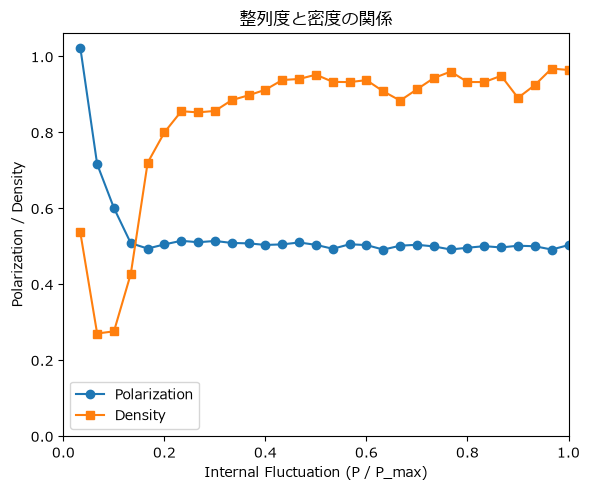

In [12]:
# ------------------- 
# 実行(複数シードの平均)
# -------------------

P_values = np.arange(1, 31)   # P = 1〜30 を試す
seeds = range(20)             # seed 0〜19 の20本で平均を取る
alpha = 0.4
Ls = 20

result = sweep_internal_fluctuation_multiseed(
    P_values, seeds,
    P_max=30,
    N=100, S=50, L=4.0, alpha=alpha,
    R_Nf=2, R_M=3, c=2, Ls=Ls,
    n_transient=200, n_measure=200,
)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(result["internal_fluctuation"], result["polarization_mean"], marker="o", label="Polarization")
ax.plot(result["internal_fluctuation"], result["density_mean"], marker="s", label="Density")
ax.set_xlabel("Internal Fluctuation (P / P_max)")
ax.set_ylabel("Polarization / Density")
ax.set_title("整列度と密度の関係")
ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)
ax.legend()
plt.tight_layout()
plt.show()

import os

save_dir = "data"
os.makedirs(save_dir, exist_ok=True)

fname = os.path.join(save_dir, f"fig10_alpha{alpha:.2f}_LS{Ls:.0f}_round.png")
fig.savefig(fname, dpi=150)

P sweep: 100%|██████████| 30/30 [00:34<00:00,  1.15s/it]


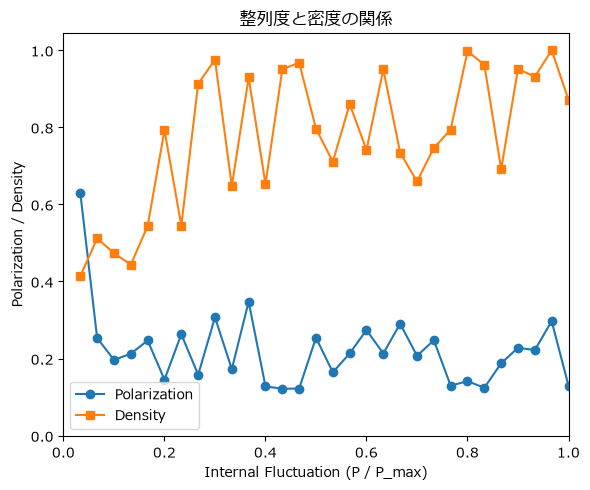

In [8]:
alpha = 0.7

# --- Fig.10 (With Potential Resonance) の再現 ---
P_max = 30
P_values = np.arange(1, 31)

results = sweep_internal_fluctuation(
    P_values, P_max=P_max,
    N=100, S=50, L=4.0, alpha=alpha, R_Nf=2, R_M=3, c=2,
    Ls=25, n_transient=100, n_measure=100, seed=0,
)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(results["internal_fluctuation"], results["polarization"], marker="o", label="Polarization")
ax.plot(results["internal_fluctuation"], results["density"], marker="s", label="Density")
ax.set_xlabel("Internal Fluctuation (P / P_max)")
ax.set_ylabel("Polarization / Density")
ax.set_title("整列度と密度の関係")
ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
import os
import pickle

# ------------------- 
#        実行
# -------------------

alpha_list = [0.3, 0.4, 0.5, 0.6, 0.7]
P_max = 30
P_values = np.arange(1, 31)
seeds = range(10)

save_dir = "data"
os.makedirs(save_dir, exist_ok=True)

all_results = {}

for alpha in tqdm(alpha_list, desc="alpha sweep"):
    results = sweep_internal_fluctuation_multiseed(
        P_values, seeds, P_max=P_max,
        N=100, S=50, L=4.0, alpha=alpha, R_Nf=2, R_M=3, c=2,
        Ls=15, n_transient=200, n_measure=1000,
    )
    all_results[alpha] = results

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(results["internal_fluctuation"], results["polarization_mean"], marker="o", label="Polarization")
    ax.plot(results["internal_fluctuation"], results["density_mean"], marker="s", label="Density")
    ax.set_xlabel("Internal Fluctuation (P / P_max)")
    ax.set_ylabel("Polarization / Density")
    ax.set_title(f"整列度と密度の関係 (alpha={alpha})")
    ax.set_xlim(0, 1)
    ax.set_ylim(bottom=0)
    ax.legend()
    plt.tight_layout()
    plt.show()

    fname = os.path.join(save_dir, f"fig10_alpha{alpha:.2f}_LS{Ls:.0f}_round.png")
    fig.savefig(fname, dpi=150)

# ---- 生データも保存(再プロットしたくなったときに再計算しなくて済むように) ----
with open(os.path.join(save_dir, "all_results.pkl"), "wb") as f:
    pickle.dump(all_results, f)

print(f"{len(alpha_list)}個のalphaについて図を '{save_dir}/' に保存しました。")

### 論文1　図13、14

In [20]:
def polarization1(displacement, L):
    """
    整列度：全個体の変位ベクトルの平均ベクトルの長さ / L
    （速さの違いも反映される。動かなかった個体は 0 ベクトル）
    """
    N = displacement.shape[0]
    mean_vec = displacement.sum(axis=0) / N
    return np.linalg.norm(mean_vec) / L


def density_sliding(position, S, Ls):
    """
    密度：Ls×Ls の窓をトーラス上で全位置にずらしたときの最大個体数 / 全個体数
    （格子を縦横2枚ずつ並べて累積和をとり、全部の窓の個体数を一度に計算する）
    """
    g = np.zeros((S, S), dtype=int)
    g[position[:, 0], position[:, 1]] = 1
    c = np.pad(np.tile(g, (2, 2)), ((1, 0), (1, 0))).cumsum(0).cumsum(1)
    win = c[Ls:Ls + S, Ls:Ls + S] - c[:S, Ls:Ls + S] - c[Ls:Ls + S, :S] + c[:S, :S]
    return win.max() / len(position)


def run_and_measure(model, n_steps, burn_in, ls_list):
    """
    model を n_steps 回進め、burn_in 以降の毎ステップで
    [整列度, 密度(Ls=ls_list[0]), 密度(Ls=ls_list[1]), ...] を記録する
    """
    rec = []
    for t in range(n_steps):
        model.step()
        if t < burn_in:
            continue
        d = model.last_displacement          # トーラスの端をまたいだ分は補正済み
        rec.append([polarization1(d, model.L)]
                   + [density_sliding(model.position, model.S, Ls) for Ls in ls_list])
    return np.array(rec)

def collect_points(records, alpha_range, P_range, Ls):
    """α と P の範囲に入る条件の (整列度, 密度) を全ステップぶんまとめて返す"""
    lo, hi = alpha_range
    pmin, pmax = P_range
    j = 1 + LS_LIST.index(Ls)
    pts = [r[:, [0, j]] for (a, P), r in records.items()
           if lo - 1e-9 <= a <= hi + 1e-9 and pmin <= P <= pmax]
    return np.concatenate(pts)


def draw_hist(ax, pts, title, den_max=1.0, bins=24):
    """整列度-密度の 2 次元ヒストグラム（論文と同じ向き：横＝整列度、縦＝密度）"""
    ax.hist2d(pts[:, 0], pts[:, 1], bins=bins, range=[[0, 1], [0, den_max]], cmap="GnBu")
    ax.set_title(title)
    ax.set_xlabel("Polarization")
    r = np.corrcoef(pts[:, 0], pts[:, 1])[0, 1]
    print(f"{title}: 整列度 平均 {pts[:, 0].mean():.2f} / 密度 平均 {pts[:, 1].mean():.2f} / 相関 {r:.2f}")

In [22]:
import time

# ---- シミュレーションの設定 ----
ALPHAS  = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]   # 0.05 刻み（帯の境目は両側の帯に入る）
PS      = [10, 12, 14, 16, 18, 20]
SEEDS   = [0, 1]
N_STEPS = 400            # 1回の実行のステップ数
BURN_IN = 200            # 最初の 200 ステップは群れができるまでの助走として捨てる
LS_LIST = [10,15,20]    # 密度を測る窓の一辺（全部いっぺんに記録しておく）

# records[(alpha, P)] = shape (シード数 × (N_STEPS - BURN_IN), 1 + len(LS_LIST))
#   [:, 0] = 整列度, [:, 1:] = LS_LIST の順の密度
records = {}
t0 = time.time()
for a in ALPHAS:
    for P in PS:
        rec = [
            run_and_measure(
                SoldierCrabSwarm_ex_v2(P=P, alpha=a, seed=s),
                N_STEPS, BURN_IN, LS_LIST,
            )
            for s in SEEDS
        ]
        records[(a, P)] = np.concatenate(rec)
    print(f"α={a} 完了（経過 {time.time() - t0:.0f} 秒）")

# 計算結果を保存しておくと、描画だけやり直せる
np.save("records_fig13_14.npy", records, allow_pickle=True)
# 読み込むとき: records = np.load("records_fig13_14.npy", allow_pickle=True).item()

α=0.2 完了（経過 19 秒）
α=0.25 完了（経過 44 秒）
α=0.3 完了（経過 72 秒）
α=0.35 完了（経過 99 秒）
α=0.4 完了（経過 126 秒）
α=0.45 完了（経過 153 秒）
α=0.5 完了（経過 180 秒）
α=0.55 完了（経過 208 秒）
α=0.6 完了（経過 234 秒）


Fig.13A  α=0.2–0.5, P=15–20: 整列度 平均 0.43 / 密度 平均 0.88 / 相関 0.02


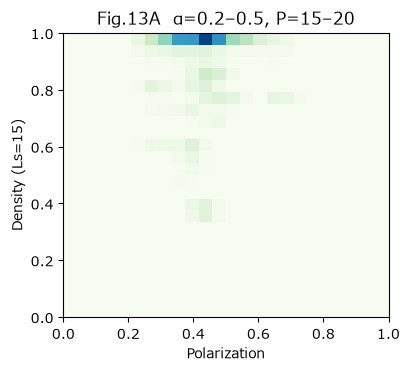

In [23]:
# 図13
LS = 15          # LS_LIST の中から選ぶ

fig, ax = plt.subplots(figsize=(4.2, 3.8))
pts = collect_points(records, alpha_range=(0.2, 0.5), P_range=(15, 20), Ls=LS)
draw_hist(ax, pts, "Fig.13A  α=0.2–0.5, P=15–20")
ax.set_ylabel(f"Density (Ls={LS})")
plt.tight_layout()
plt.show()

α=0.5–0.6: 整列度 平均 0.31 / 密度 平均 0.92 / 相関 0.10
α=0.4–0.5: 整列度 平均 0.38 / 密度 平均 0.89 / 相関 -0.02
α=0.3–0.4: 整列度 平均 0.43 / 密度 平均 0.89 / 相関 -0.06
α=0.2–0.3: 整列度 平均 0.48 / 密度 平均 0.85 / 相関 0.09


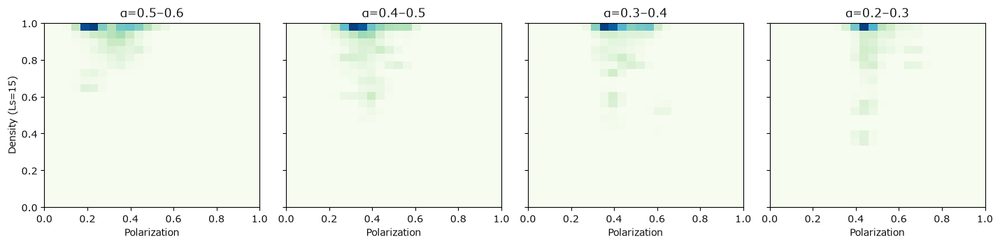

In [24]:
# 図14
LS = 15
BANDS = [(0.5, 0.6), (0.4, 0.5), (0.3, 0.4), (0.2, 0.3)]

fig, axs = plt.subplots(1, len(BANDS), figsize=(3.6 * len(BANDS), 3.6), sharey=True)
for ax, band in zip(axs, BANDS):
    pts = collect_points(records, alpha_range=band, P_range=(10, 20), Ls=LS)
    draw_hist(ax, pts, f"α={band[0]}–{band[1]}")
axs[0].set_ylabel(f"Density (Ls={LS})")
plt.tight_layout()
plt.show()

### 論文2　図3bc

config: 100%|██████████| 3/3 [02:45<00:00, 55.33s/it]


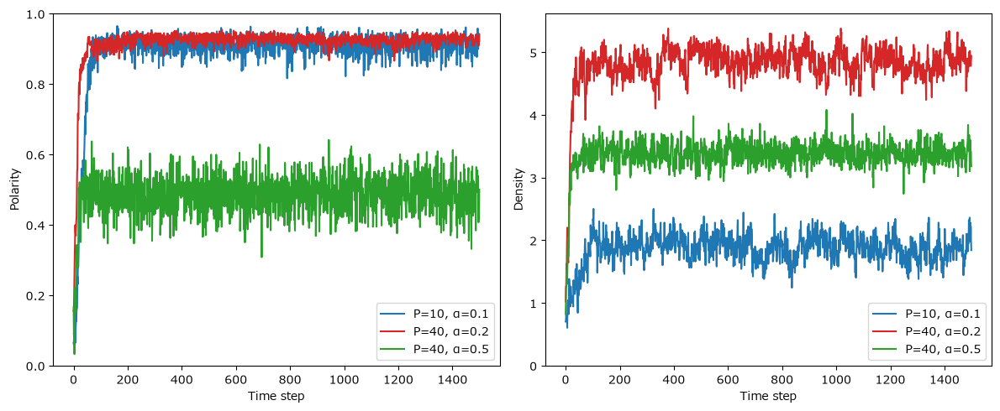

In [11]:
# ============================================================
# 整列度・密度の「時間発展」を、3つの(P, alpha)設定で比較する
# ============================================================

def torus_displacement(pos_before, pos_after, S):
    diff = pos_after.astype(float) - pos_before.astype(float)
    diff = (diff + S / 2) % S - S / 2
    return diff

# def polarization(theta):
#     """
#     基本ベクトル（theta で表される向き）の平均の長さを整列度として返す。

#     Parameters
#     ----------
#     theta : np.ndarray, shape (N,)
#         各エージェントの基本ベクトルの向き（ラジアン）
#     """
#     unit_vecs = np.stack([np.cos(theta), np.sin(theta)], axis=1)  # (N, 2)
#     mean_vec = unit_vecs.mean(axis=0)
#     return np.linalg.norm(mean_vec)

# def polarization(displacement):
#     N = displacement.shape[0]
#     speeds = np.linalg.norm(displacement, axis=1)
#     moved = speeds > 1e-9

#     unit_vecs = np.zeros_like(displacement, dtype=float)
#     unit_vecs[moved] = displacement[moved] / speeds[moved, None]

#     mean_vec = unit_vecs.sum(axis=0) / N
#     return np.linalg.norm(mean_vec)

def polarization2(displacement):
    """
    論文2 (Emergence of a coherent and cohesive swarm) の整列度
    ------------------------------------------------
    Polarity = 各個体の単位速度ベクトルの平均ベクトルの長さ
    （各個体ごとに正規化してから平均するので、向きの一致度だけを見る。値は常に[0,1]）

    P = || (1/N) * Σ (v_i / |v_i|) ||
    """
    N = displacement.shape[0]
    speeds = np.linalg.norm(displacement, axis=1)
    moved = speeds > 1e-9

    unit_vecs = np.zeros_like(displacement, dtype=float)
    unit_vecs[moved] = displacement[moved] / speeds[moved, None]

    mean_vec = unit_vecs.sum(axis=0) / N
    return np.linalg.norm(mean_vec)

def density_paper2(positions, S, include_self=False):
    """
    密度 (Density) = 3x3近傍にいる個体数の平均
    論文2 Fig.3c の "the number of neighbors" は自分を含まない方が自然なのでデフォルトは include_self=False
    """
    occ = np.zeros((S, S), dtype=int)
    np.add.at(occ, (positions[:, 0], positions[:, 1]), 1)
    neighbor_sum = np.zeros_like(occ)
    for dx in (-1, 0, 1):
        for dy in (-1, 0, 1):
            neighbor_sum += np.roll(np.roll(occ, -dx, axis=0), -dy, axis=1)
    counts = neighbor_sum[positions[:, 0], positions[:, 1]]
    if not include_self:
        counts = counts - 1
    return counts.mean()

def run_time_series(P, alpha, N=100, S=50, L=6.0, R_Nf=2, R_M=3, c=2,
                     omega=5.0, n_steps=1000, seed=0):
    """
    swarm_cls (SoldierCrabSwarm_noVM を想定) を n_steps 分回して、
    各ステップの整列度・密度を記録する
    """
    # swarm = SoldierCrabSwarm_noVM(N=N, S=S, L=L, P=P, alpha=alpha, R_Nf=R_Nf, R_M=R_M, c=c, omega=omega, seed=seed)
    # swarm = SoldierCrabSwarm_step_noVM(N=N, S=S, L=L, P=P, alpha=alpha, R_Nf=R_Nf, R_M=R_M, c=c, omega=omega, seed=seed)
    # swarm = SoldierCrabSwarm(N=N, S=S, L=L, P=P, alpha=alpha, R_Nf=R_Nf, R_M=R_M, c=c, seed=seed)
    # swarm = SoldierCrabSwarm_step(N=N, S=S, L=L, P=P, alpha=alpha, R_Nf=R_Nf, R_M=R_M, c=c, seed=seed)
    swarm = SoldierCrabSwarm_step_pop(N=N, S=S, L=L, P=P, alpha=alpha, R_Nf=R_Nf, R_M=1, c=c, seed=seed)
    # swarm = SoldierCrabSwarm_step_popVM(N=N, S=S, L=L, P=P, alpha=alpha, R_Nf=R_Nf, R_M=R_M, c=c, seed=seed)
    # swarm = SoldierCrabSwarm_step_pop_noVM(N=N, S=S, L=L, P=P, alpha=alpha, R_Nf=R_Nf, R_M=R_M, c=c, omega=0.2, seed=seed)
    # swarm = SoldierCrabSwarm_step_recalc(N=N, S=S, L=L, P=P, alpha=alpha, R_Nf=R_Nf, R_M=R_M, c=c, seed=seed)
    # swarm = SoldierCrabSwarm_step_pop_dynamic(N=N, S=S, L=L, P=P, alpha=alpha, R_Nf=R_Nf, R_M=R_M, c=c, seed=seed)

    pol_series = np.zeros(n_steps)
    den_series = np.zeros(n_steps)

    prev_pos = swarm.position.copy()
    for t in range(n_steps):
        swarm.step()
        disp = torus_displacement(prev_pos, swarm.position, S)
        pol_series[t] = polarization2(disp)
        den_series[t] = density_paper2(swarm.position, S)
        prev_pos = swarm.position.copy()

    return pol_series, den_series

# ============================================================
# 論文2 Fig.3b, 3c の3パターン (色も論文に合わせる)
# ============================================================
configs = [
    {"P": 10, "alpha": 0.1, "color": "tab:blue",  "label": "P=10, α=0.1"},
    {"P": 40, "alpha": 0.2, "color": "tab:red",   "label": "P=40, α=0.2"},
    {"P": 40, "alpha": 0.5, "color": "tab:green", "label": "P=40, α=0.5"},
]

n_steps = 1500
seed = 0
results = {}
for cfg in tqdm(configs, desc="config"):
    pol_series, den_series = run_time_series(
        P=cfg["P"], alpha=cfg["alpha"], n_steps=n_steps, seed=seed
    )
    results[cfg["label"]] = (pol_series, den_series, cfg["color"])

# ============================================================
# 描画: (b) Polarity vs step / (c) Density vs step
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for label, (pol_series, den_series, color) in results.items():
    axes[0].plot(pol_series, color=color, label=label)
    axes[1].plot(den_series, color=color, label=label)

axes[0].set_xlabel("Time step")
axes[0].set_ylabel("Polarity")
axes[0].set_ylim(0, 1)
axes[0].legend()

axes[1].set_xlabel("Time step")
axes[1].set_ylabel("Density")
axes[1].set_ylim(bottom=0)
axes[1].legend()

plt.tight_layout()
# fig.savefig("fig3bc_noVM.png", dpi=150)
plt.show()

# スケールフリー相関

In [ ]:
def compute_velocities(pos_now, pos_next, S, tau=1):
    """
    トーラスの周期境界を考慮した変位から速度を作る (N, 2)
    tau ステップ分の変位を tau で割る（tau>1 にすると1ステップ毎のジャンプのノイズが平均化される）
    """
    d = (pos_next - pos_now).astype(float)
    d = (d + S / 2) % S - S / 2          # 最短の変位（壁またぎ対策）
    return d / tau


def correlation_function(positions, velocities, S, bin_width=1.0, r_max=None, min_pairs=10):
    """
    1スナップショットの相関関数 C(r) を距離ビンごとに計算する（C(0)=1 に規格化）

    Returns
    -------
    (r, C, n_pairs) : ペア数が min_pairs 未満のビンは除外。計算不能なら None
    """
    N = len(positions)
    if r_max is None:
        r_max = S / 2                    # トーラスでは S/2 を超えると円環が途切れるので打ち切り

    u = velocities - velocities.mean(axis=0)          # 揺らぎベクトル u_i
    c0 = np.mean(np.sum(u ** 2, axis=1))              # 規格化用 C(0) = <u_i・u_i>
    if c0 == 0:
        return None

    # 全ペアの最短距離（minimum image）
    diff = positions[:, None, :] - positions[None, :, :]
    diff = (diff + S / 2) % S - S / 2
    dist = np.sqrt((diff ** 2).sum(axis=-1))
    dots = u @ u.T                                    # u_i・u_j

    iu = np.triu_indices(N, k=1)                      # i<j のペアだけ使う
    r, c = dist[iu], dots[iu]

    # 距離ビンごとに平均
    edges = np.arange(0.0, r_max + bin_width, bin_width)
    nb = len(edges) - 1
    idx = np.digitize(r, edges) - 1
    ok = (idx >= 0) & (idx < nb)
    sums = np.bincount(idx[ok], weights=c[ok], minlength=nb)
    cnts = np.bincount(idx[ok], minlength=nb)

    good = cnts >= min_pairs
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers[good], sums[good] / cnts[good] / c0, cnts[good]


def find_correlation_length(r, C):
    """C(r) が正→負に最初に切り替わる点を線形補間して ξ とする。見つからなければ nan"""
    if len(C) < 2 or C[0] <= 0:
        return np.nan
    for i in range(len(C) - 1):
        if C[i] > 0 and C[i + 1] <= 0:
            return r[i] + (r[i + 1] - r[i]) * C[i] / (C[i] - C[i + 1])
    return np.nan


def analyze_scale_free(history, S, tau=1, t_list=None, bin_width=1.0, min_pairs=10, verbose=True):
    """
    history : model.run(..., record_history=True) の戻り値 (T+1, N, 2)
    tau     : 速度を何ステップ分の変位から作るか（時刻 t の速度 = (pos[t+tau]-pos[t])/tau）
    t_list  : 解析する時刻（省略時は解析可能な全時刻）
    Returns : スナップショットごとの dict(t, r, C, xi) のリスト（ξ が定義できたものだけ）
    """
    T = history.shape[0] - 1
    if t_list is None:
        t_list = range(0, T - tau + 1)
    results, skipped = [], 0
    for t in t_list:
        if t + tau > T:
            continue
        v = compute_velocities(history[t], history[t + tau], S, tau)
        out = correlation_function(history[t], v, S, bin_width, min_pairs=min_pairs)
        if out is None:
            skipped += 1
            continue
        r, C, _ = out
        xi = find_correlation_length(r, C)
        if np.isnan(xi):
            skipped += 1
            continue
        results.append(dict(t=t, r=r, C=C, xi=xi))
    if verbose:
        print(f"[tau={tau}] 解析できた: {len(results)} 件 / ξ が定義できず除外: {skipped} 件")
    return results


def fit_rescaled(results, fit_range=(0.0, 1.2)):
    """全スナップショットの (r/ξ, C) をまとめて直線フィットして 傾き・切片・R^2 を返す"""
    x = np.concatenate([d["r"] / d["xi"] for d in results])
    y = np.concatenate([d["C"] for d in results])
    m = (x >= fit_range[0]) & (x <= fit_range[1])
    slope, intercept = np.polyfit(x[m], y[m], 1)
    pred = slope * x[m] + intercept
    r2 = 1 - np.sum((y[m] - pred) ** 2) / np.sum((y[m] - y[m].mean()) ** 2)
    return dict(slope=slope, intercept=intercept, r2=r2, n_points=int(m.sum()))


def plot_scale_free(results, fit_range=(0.0, 1.2), max_curves=8, title=None, ylim=(-1.2, 1.2)):
    """左: C(r) と ξ / 右: C を r/ξ に対してプロット（論文 Fig.15 b, c, d 相当）"""
    fit = fit_rescaled(results, fit_range)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

    step = max(1, len(results) // max_curves)
    for d in results[::step][:max_curves]:
        ax[0].plot(d["r"], d["C"], "o-", ms=3, alpha=0.7, label=f"t={d['t']} (xi={d['xi']:.1f})")
        ax[0].axvline(d["xi"], ls=":", alpha=0.3)
    ax[0].axhline(0, color="k", lw=0.8)
    ax[0].set(xlabel="Distance r", ylabel="Correlation function C(r)", title="(a) C(r) and correlation length xi")
    ax[0].legend(fontsize=7)

    for d in results:
        ax[1].plot(d["r"] / d["xi"], d["C"], ".", alpha=0.35, color="tab:blue")
    xs = np.linspace(0, 1.6, 50)
    ax[1].plot(xs, fit["slope"] * xs + fit["intercept"], "r-", lw=2,
               label=f"fit (r/xi in {fit_range}): slope={fit['slope']:.2f}, "
                     f"intercept={fit['intercept']:.2f}, R2={fit['r2']:.2f}")
    ax[1].axhline(0, color="k", lw=0.8)
    ax[1].set_xlim(0, 1.6)
    ax[1].set_ylim(*ylim)
    ax[1].set(xlabel="Rescaled distance r/xi", ylabel="Correlation function C",
              title=f"(b) Rescaled ({len(results)} snapshots)")
    ax[1].legend(fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    return fit


def scan_tau(history, S, taus=(1, 3, 5, 10, 20, 40), t_step=3, **kwargs):
    """速度を作る間隔 tau を変えて、ξ・傾き・切片・R^2 を一覧表示する"""
    print(f"{'tau':>4} {'n':>5} {'xi_mean':>8} {'xi_std':>7} {'slope':>7} {'icpt':>7} {'R2':>6}")
    rows = {}
    for tau in taus:
        res = analyze_scale_free(history, S, tau=tau, t_list=range(0, history.shape[0] - tau, t_step),
                                 verbose=False, **kwargs)
        if len(res) < 3:
            print(f"{tau:>4} {len(res):>5}   (too few snapshots)")
            continue
        f = fit_rescaled(res)
        xis = [d["xi"] for d in res]
        print(f"{tau:>4} {len(res):>5} {np.mean(xis):>8.2f} {np.std(xis):>7.2f} "
              f"{f['slope']:>7.3f} {f['intercept']:>7.3f} {f['r2']:>6.2f}")
        rows[tau] = res
    return rows

In [ ]:
# 実行して履歴を保存

S = 50
model = SoldierCrabSwarm_step_pop(N=100, S=S, L=4, P=20, alpha=0.7, R_Nf=2, R_M=3, seed=0)

model.run(500)                                   # ウォームアップ（記録しない）
history = model.run(600, record_history=True)    # 記録する  shape = (601, N, 2)
print(history.shape)

In [ ]:
# プロット
results = analyze_scale_free(history, S, tau=20, t_list=range(0, 580, 3))
fit = plot_scale_free(results, fit_range=(0.0, 1.2), title="tau=20")
print(fit)